In [2]:
# 1) Importar librerías
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

In [3]:
# 2) Generar datos sintéticos
X, y_true = make_blobs(
    n_samples=750,
    centers=[(1, 1), (-1, -1), (1, -1)],
    cluster_std=0.4,
    random_state=42
)

In [ ]:
################# qué tipo de dato es X

In [92]:
############# qué forma tienen mis datos, cuántas filas tengo....



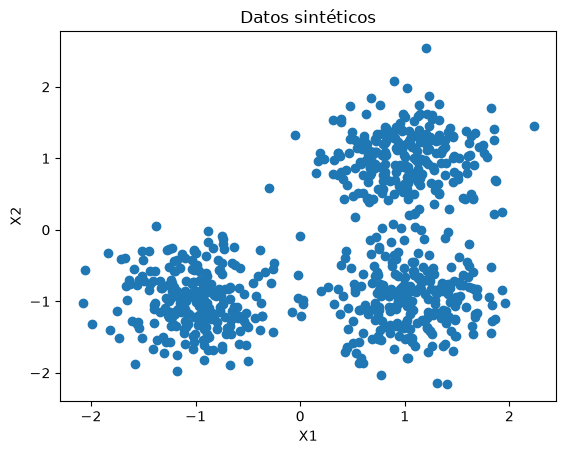

In [11]:
plt.scatter(X[:, 0], X[:, 1])
plt.title("Datos sintéticos")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

In [12]:
# 3) Escalar los datos (recomendado para DBSCAN)
####################################################
####################################################
##########TENGO LEAKAGE?############################

X = StandardScaler().fit_transform(X)

In [86]:
# 4) Aplicar DBSCAN
dbscan = DBSCAN(eps=0.3, min_samples=14)
labels = dbscan.fit_predict(X)

Clústeres detectados: 3
Puntos de ruido (-1): 28
Etiquetas únicas: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2)]


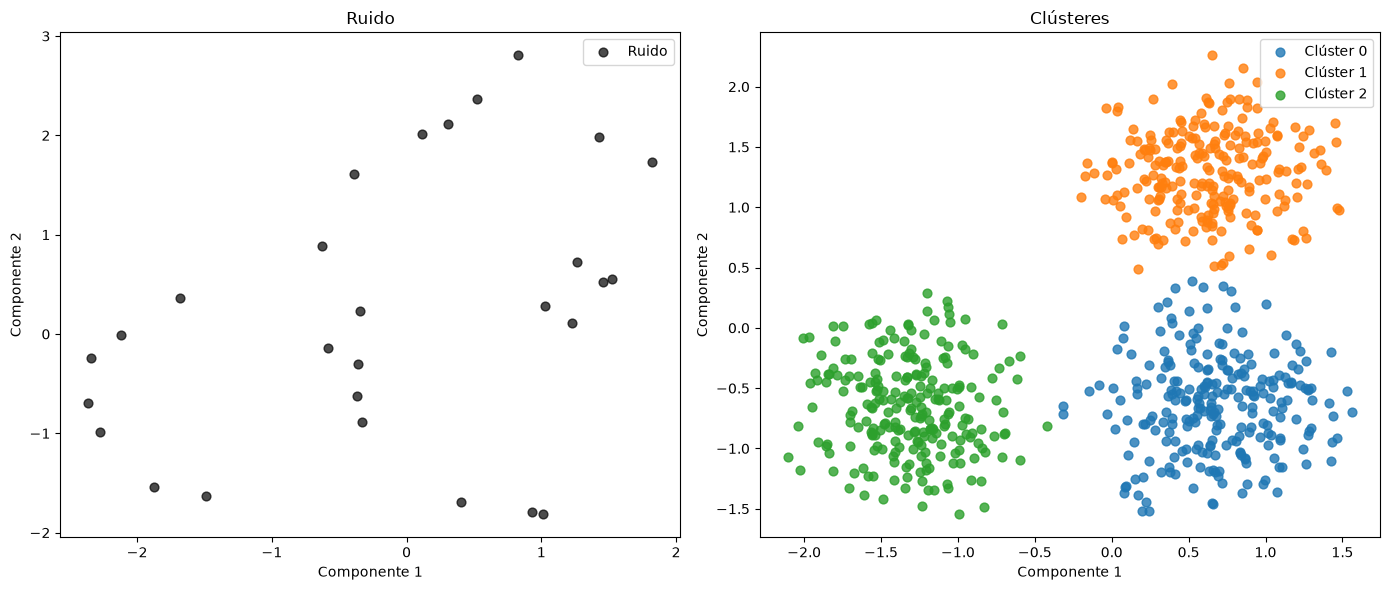

In [87]:
# 5) Resumen de resultados
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print(f"Clústeres detectados: {n_clusters}")
print(f"Puntos de ruido (-1): {n_noise}")
print(f"Etiquetas únicas: {sorted(set(labels))}")

# 6) Visualización: ruido y clústeres lado a lado
fig, (ax_ruido, ax_clusters) = plt.subplots(1, 2, figsize=(14, 6))

# --- Ruido en negro (izquierda) ---
noise_mask = labels == -1

ax_ruido.scatter(
    X[noise_mask, 0],
    X[noise_mask, 1],
    c="black",
    s=40,
    label="Ruido",
    alpha=0.7
)

ax_ruido.set_title("Ruido")
ax_ruido.set_xlabel("Componente 1")
ax_ruido.set_ylabel("Componente 2")
ax_ruido.legend()

# --- Clústeres con colores (derecha) ---
for cluster in sorted(set(labels)):
    if cluster == -1:
        continue

    mask = labels == cluster

    ax_clusters.scatter(
        X[mask, 0],
        X[mask, 1],
        s=40,
        label=f"Clúster {cluster}",
        alpha=0.8
    )

ax_clusters.set_title("Clústeres")
ax_clusters.set_xlabel("Componente 1")
ax_clusters.set_ylabel("Componente 2")
ax_clusters.legend()

plt.tight_layout()
plt.show()

Mapeo DBSCAN -> y_true:
{np.int64(0): np.int64(2), np.int64(1): np.int64(0), np.int64(2): np.int64(1)}

Puntos bien clasificados: 719 / 750
Puntos mal clasificados o ruido: 31


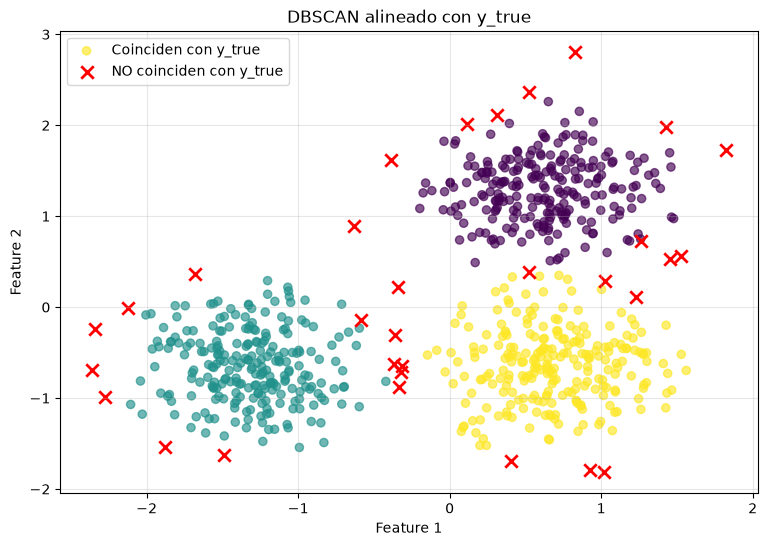

In [98]:
# 5) Alinear DBSCAN con y_true usando la clase mayoritaria de cada cluster
import numpy as np
import matplotlib.pyplot as plt

# Clases reales
true_classes = np.unique(y_true)

# Clusters detectados por DBSCAN, sin incluir el ruido (-1)
dbscan_clusters = np.unique(labels[labels != -1])

# Diccionario: etiqueta original de DBSCAN -> etiqueta real
label_mapping = {}

for cluster in dbscan_clusters:
    # Puntos asignados a este cluster por DBSCAN
    mask_cluster = labels == cluster

    # Clases reales de esos puntos
    true_labels_in_cluster = y_true[mask_cluster]

    # Clase real más frecuente dentro del cluster
    values, counts = np.unique(true_labels_in_cluster, return_counts=True)
    majority_class = values[np.argmax(counts)]

    label_mapping[cluster] = majority_class

print("Mapeo DBSCAN -> y_true:")
print(label_mapping)

# Crear etiquetas alineadas
labels_aligned = np.array([
    label_mapping.get(label, -1) if label != -1 else -1
    for label in labels
])

# Comparación con y_true
matches = labels_aligned == y_true
mismatches = ~matches

print(f"\nPuntos bien clasificados: {matches.sum()} / {len(y_true)}")
print(f"Puntos mal clasificados o ruido: {mismatches.sum()}")

# 6) Gráfico
plt.figure(figsize=(9, 6))

# Puntos correctos
plt.scatter(
    X[matches, 0], X[matches, 1],
    c=labels_aligned[matches],
    cmap="viridis",
    s=35,
    alpha=0.65,
    label="Coinciden con y_true"
)

# Puntos incorrectos o ruido
plt.scatter(
    X[mismatches, 0], X[mismatches, 1],
    c="red",
    marker="x",
    s=80,
    linewidths=2,
    label="NO coinciden con y_true"
)

plt.title("DBSCAN alineado con y_true")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()